# MentorIA Tech — comparação justa de 3 modelos e validação de saturação
**MVP independente do backend.** Dados sintéticos, cotas ilustrativas, horizonte de 30 dias. Chaves Gemini de projetos distintos. O banco SQLite é apenas diagnóstico, **não** treina o modelo. As trajetórias de usuários são **hipóteses de cenário**, não previsões de aquisição de usuários.

A: RF direto · B: RF ajustado por `TimeSeriesSplit` · C: RF de taxas por usuário. Mesmo teste cronológico, cenários e sementes. Uma saturação é **≥5% de chamadas recusadas em um dia**. O simulador usa um único tipo de chamada e limites simplificados, não as cotas de todos os modelos Gemini.

In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, r2_score

SEED = 42
HORIZONTE = 30
N_CENARIOS = 60
LIMIAR = .05
CHAMADAS_POR_USUARIO = 5
TOKENS_POR_CHAMADA = 2500
DATA_INICIO = pd.Timestamp('2026-11-16')
COTAS = {
    'Gemini — Chave 1': {'rpm':5,'tpm':250_000,'rpd':20},
    'Gemini — Chave 2': {'rpm':5,'tpm':250_000,'rpd':20},
    'Groq': {'rpm':30,'tpm':8_000,'rpd':1000},
}
print('Cotas demonstrativas:', COTAS)

Cotas demonstrativas: {'Gemini — Chave 1': {'rpm': 5, 'tpm': 250000, 'rpd': 20}, 'Gemini — Chave 2': {'rpm': 5, 'tpm': 250000, 'rpd': 20}, 'Groq': {'rpm': 30, 'tpm': 8000, 'rpd': 1000}}


## 1. Telemetria disponível (diagnóstico)
A telemetria real é curta e incompleta para treinamento supervisionado confiável; não a misturamos silenciosamente com os dados sintéticos.

In [2]:
DB = Path('novamente.db')
if DB.exists():
    with sqlite3.connect(DB.resolve().as_uri()+'?mode=ro', uri=True) as con:
        h = pd.read_sql_query('SELECT data_hora, provedor, operacao, codigo_http, tokens_totais FROM telemetria_api', con)
    print(f'SQLite: {len(h)} chamadas; {(h.codigo_http == 429).sum()} HTTP 429; {h.tokens_totais.notna().sum()} com tokens.')
else:
    print('SQLite não encontrado; comparação sintética funciona normalmente.')

SQLite não encontrado; comparação sintética funciona normalmente.


## 2. Treino e teste cronológicos
O gerador simula dias úteis/fins de semana, variação individual de uso e de tokens. A última fração de 20% fica **intocada** durante a otimização. Modelo C prevê `chamadas/usuário` e `tokens/chamada` (taxas) para permitir crescimento fora da faixa observada; a conversão para totais usa apenas o número de usuários assumido no cenário.

In [3]:
def criar_dados(dias=300, seed=SEED):
    rng = np.random.default_rng(seed)
    datas = pd.date_range('2026-01-01', periods=dias, freq='D')
    usuarios = np.maximum(1, np.rint(np.linspace(5, 110, dias) * rng.lognormal(0,.12,dias))).astype(int)
    semana = np.where(datas.dayofweek >= 5, .70, 1.)
    # Mudanças moderadas de comportamento ao longo do tempo, sem usar o futuro como feature.
    uso = np.clip(CHAMADAS_POR_USUARIO * (1 + .12*np.sin(np.arange(dias)/23)), 1, None)
    chamadas = rng.poisson(usuarios * semana * uso)
    tokens_chamada = np.clip(rng.normal(TOKENS_POR_CHAMADA, 280, dias), 300, None)
    tokens = np.rint(chamadas * tokens_chamada).astype(int)
    return pd.DataFrame({'data':datas,'usuarios':usuarios,'dia_semana':datas.dayofweek,
                         'chamadas':chamadas,'tokens':tokens,
                         'taxa_chamadas':chamadas/usuarios,
                         'taxa_tokens':np.where(chamadas>0,tokens/np.maximum(chamadas,1),TOKENS_POR_CHAMADA)})

dados = criar_dados()
corte = int(len(dados)*.8)
treino, teste = dados.iloc[:corte].copy(), dados.iloc[corte:].copy()
XCOL = ['usuarios','dia_semana']
TCOL = ['dia_semana'] # taxas não dependem do número de usuários, evitando extrapolação da taxa
YCOL = ['chamadas','tokens']
print('Treino:', len(treino), 'dias | Teste:',len(teste),'dias | usuários treino:',treino.usuarios.min(),'-',treino.usuarios.max())

Treino: 240 dias | Teste: 60 dias | usuários treino: 5 - 114


## 3. Três modelos
A é o modelo original. B testa 18 configurações com divisão temporal apenas no treino. C prevê taxas por usuário e tokens por chamada, reconstruindo totais. A baseline constante é incluída como controle.

In [4]:
A = RandomForestRegressor(n_estimators=80,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
A.fit(treino[XCOL], treino[YCOL])
parametros = {'n_estimators':[80,150,250], 'max_depth':[5,10,15,None],
              'min_samples_split':[2,5,10], 'min_samples_leaf':[1,3,5],
              'max_features':[.7,1.]}
busca = RandomizedSearchCV(
    RandomForestRegressor(random_state=SEED,n_jobs=1), parametros,
    n_iter=18, cv=TimeSeriesSplit(n_splits=4), scoring='neg_mean_absolute_error',
    random_state=SEED,n_jobs=-1,refit=True)
# Escalonamento evita que o alvo tokens domine a busca por sua magnitude.
escala = treino[YCOL].mean().to_numpy()
busca.fit(treino[XCOL], treino[YCOL]/escala)
B = busca.best_estimator_
C = RandomForestRegressor(n_estimators=150,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
C.fit(treino[TCOL],treino[['taxa_chamadas','taxa_tokens']])
print('Melhores parâmetros B:',busca.best_params_)

def prever(nome, frame):
    if nome=='A — RF direto':
        y = A.predict(frame[XCOL])
    elif nome=='B — RF otimizado':
        y = B.predict(frame[XCOL])*escala
    elif nome=='C — RF por usuário':
        taxas = np.maximum(C.predict(frame[TCOL]),0)
        chamadas = taxas[:,0] * frame.usuarios.to_numpy()
        y = np.column_stack((chamadas, chamadas * taxas[:,1]))
    else:
        y = np.tile(treino[YCOL].mean().to_numpy(),(len(frame),1))
    return np.maximum(y,0)

NOMES = ['A — RF direto','B — RF otimizado','C — RF por usuário','Baseline média']

Melhores parâmetros B: {'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}


## 4. Validação de demanda — período futuro isolado
WAPE e MAE informam magnitude de erro; viés revela sub/superestimação; MAE nos 10% dias de maior demanda avalia picos. R² pode ser negativo. Para comparar modelos, use métricas de **teste**, não de treino.

,modelo,alvo,MAE,WAPE_%,R2,vies,MAE_picos
0,A — RF direto,chamadas,56.83,13.37,0.48,-13.92,152.03
1,A — RF direto,tokens,172018.71,16.06,0.33,-56610.35,460051.78
2,B — RF otimizado,chamadas,52.68,12.39,0.53,-9.44,147.04
3,B — RF otimizado,tokens,181111.99,16.91,0.25,-51064.20,477988.95
4,C — RF por usuário,chamadas,43.46,10.22,0.73,37.44,38.68
5,C — RF por usuário,tokens,142530.77,13.31,0.58,85630.07,118329.45
6,Baseline média,chamadas,208.31,49.01,-4.58,-208.31,383.09
7,Baseline média,tokens,533339.81,49.79,-4.03,-533339.81,1038416.87


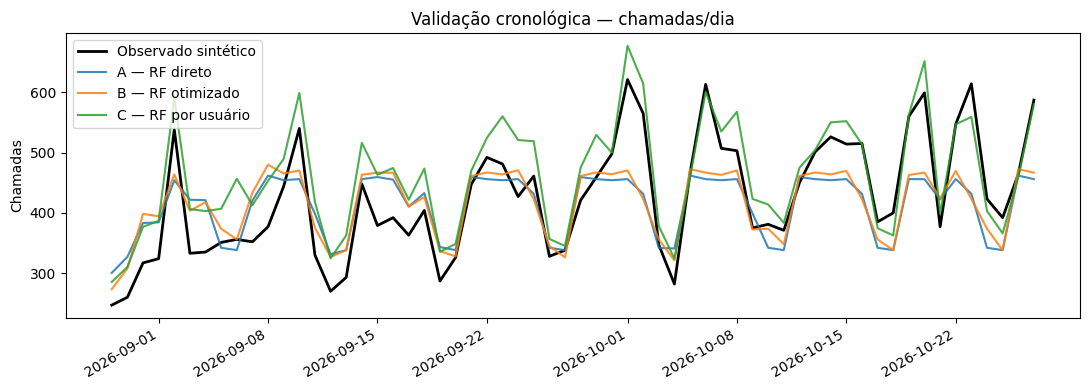

In [5]:
linhas=[]
for nome in NOMES:
    p = prever(nome,teste)
    for j,alvo in enumerate(YCOL):
        real=teste[alvo].to_numpy(); pred=p[:,j]
        picos=real>=np.quantile(real,.9)
        linhas.append({'modelo':nome,'alvo':alvo,'MAE':mean_absolute_error(real,pred),
                       'WAPE_%':100*np.abs(real-pred).sum()/max(real.sum(),1),
                       'R2':r2_score(real,pred),'vies':np.mean(pred-real),
                       'MAE_picos':mean_absolute_error(real[picos],pred[picos])})
metricas=pd.DataFrame(linhas)
display(metricas.round(2))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(teste.data,teste.chamadas,label='Observado sintético',color='black',linewidth=2)
for nome in NOMES[:-1]: ax.plot(teste.data,prever(nome,teste)[:,0],label=nome,alpha=.85)
ax.set(title='Validação cronológica — chamadas/dia',ylabel='Chamadas');ax.legend();fig.autofmt_xdate();plt.tight_layout();plt.show()

## 5. Simulador de cotas com fallback (simplificado)
Cada dia reinicia RPD. Cada minuto reinicia RPM/TPM. Usamos o **mesmo perfil de chegadas** para observar e prever; isso controla a aleatoriedade do simulador. O total de tokens é dividido igualmente por chamada no dia (simplificação). A verificação é por chamada e por recurso em ordem de fallback.

In [6]:
MINUTOS = np.arange(8*60,23*60)
PESOS = np.where((MINUTOS>=12*60)&(MINUTOS<21*60),1.5,.8).astype(float)
PESOS /= PESOS.sum()

def simular_dia(chamadas,tokens,seed):
    n_total=max(0,int(round(chamadas)))
    if n_total==0: return 0,0
    rng=np.random.default_rng(seed)
    chegadas=rng.multinomial(n_total,PESOS)
    tpc=max(1.,float(tokens)/n_total)
    uso_dia=np.zeros(3,dtype=int)
    recusadas=0
    limites=list(COTAS.values())
    for n in chegadas:
        if not n: continue
        uso_min=np.zeros(3,dtype=int)
        tokens_min=np.zeros(3,dtype=float)
        for _ in range(int(n)):
            for i,l in enumerate(limites):
                if uso_dia[i]<l['rpd'] and uso_min[i]<l['rpm'] and tokens_min[i]+tpc<=l['tpm']:
                    uso_dia[i]+=1;uso_min[i]+=1;tokens_min[i]+=tpc
                    break
            else: recusadas+=1
    return n_total,recusadas

def primeiro_dia(y,seed):
    for i,(n,t) in enumerate(y,1):
        solicitadas,recusadas=simular_dia(n,t,seed+i)
        if solicitadas and recusadas/solicitadas>=LIMIAR: return i
    return None

## 6. Validação da **data** de saturação — 60 cenários independentes
Criamos cenários de 30 dias com crescimento variado, inclusive fora da faixa de treino. Cada modelo recebe as **mesmas hipóteses de usuários**; a demanda observada é sorteada separadamente e permanece oculta dos modelos. Contamos TP/FP/FN/TN, precisão, recall e F1. O MAE da data é calculado **apenas** quando ambos os lados apresentam evento, e nunca substitui as métricas de detecção.

In [7]:
rng=np.random.default_rng(2026)
registros=[]
for c in range(N_CENARIOS):
    inicio=int(rng.integers(5,110)); crescimento=float(rng.uniform(-.01,.16))
    datas=pd.date_range(DATA_INICIO,periods=HORIZONTE)
    usuarios=np.maximum(1,np.rint(inicio*(1+crescimento)**np.arange(HORIZONTE))).astype(int)
    frame=pd.DataFrame({'usuarios':usuarios,'dia_semana':datas.dayofweek})
    semana=np.where(datas.dayofweek>=5,.70,1.)
    # Processo gerador fora do treino; sazonalidade não antecipada pelo RF.
    taxa=CHAMADAS_POR_USUARIO*(1+.12*np.sin((np.arange(HORIZONTE)+240)/23))
    real_chamadas=rng.poisson(usuarios*semana*taxa)
    real_tokens=np.rint(real_chamadas*np.clip(rng.normal(TOKENS_POR_CHAMADA,280,HORIZONTE),300,None))
    y_real=np.column_stack((real_chamadas,real_tokens))
    s=10000+c*100
    dia_real=primeiro_dia(y_real,s)
    for nome in NOMES:
        dia_prev=primeiro_dia(prever(nome,frame),s)
        registros.append({'cenario':c+1,'modelo':nome,'usuarios_iniciais':inicio,
                          'crescimento':crescimento,'dia_real':dia_real,'dia_previsto':dia_prev,
                          'TP':int(dia_real is not None and dia_prev is not None),
                          'FP':int(dia_real is None and dia_prev is not None),
                          'FN':int(dia_real is not None and dia_prev is None),
                          'TN':int(dia_real is None and dia_prev is None),
                          'erro_dias':abs(dia_prev-dia_real) if dia_real is not None and dia_prev is not None else np.nan})
validacao=pd.DataFrame(registros)
res=[]
for nome,g in validacao.groupby('modelo',sort=False):
    tp,fp,fn,tn=[int(g[x].sum()) for x in ['TP','FP','FN','TN']]
    precisao=tp/(tp+fp) if tp+fp else np.nan
    recall=tp/(tp+fn) if tp+fn else np.nan
    f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan
    res.append({'modelo':nome,'TP':tp,'FP':fp,'FN':fn,'TN':tn,
                'precisao':precisao,'recall':recall,'F1':f1,
                'MAE_dia_condicional':g.erro_dias.mean(),
                'cenarios_com_evento':tp+fn})
resumo=pd.DataFrame(res)
display(resumo.round(3))
print('Eventos reais em',N_CENARIOS,'cenários:',int(validacao[validacao.modelo==NOMES[0]].TP.sum()+validacao[validacao.modelo==NOMES[0]].FN.sum()))

,modelo,TP,FP,FN,TN,precisao,recall,F1,MAE_dia_condicional,cenarios_com_evento
0,A — RF direto,0,0,45,15,NaN,0.000,0.000,NaN,45
1,B — RF otimizado,0,0,45,15,NaN,0.000,0.000,NaN,45
2,C — RF por usuário,41,0,4,15,1.0,0.911,0.953,4.0,45
3,Baseline média,0,0,45,15,NaN,0.000,0.000,NaN,45


Eventos reais em 60 cenários: 45


## 7. Escolha transparente e diagnóstico
Critério: maior F1 na detecção de saturação, desempate por recall, depois MAE de data (quando disponível) e WAPE de chamadas. **Se todos os modelos falharem em detectar saturações, não declaramos vencedor validado.** A escolha abaixo é apenas para este experimento sintético.

,modelo,F1,recall,precisao,MAE_dia_condicional,WAPE_%,MAE_picos
2,C — RF por usuário,0.953,0.911,1.0,4.0,10.224,38.681
1,B — RF otimizado,0.000,0.000,NaN,NaN,12.395,147.037
0,A — RF direto,0.000,0.000,NaN,NaN,13.370,152.034
3,Baseline média,0.000,0.000,NaN,NaN,49.008,383.092


Melhor modelo neste experimento sintético: C — RF por usuário


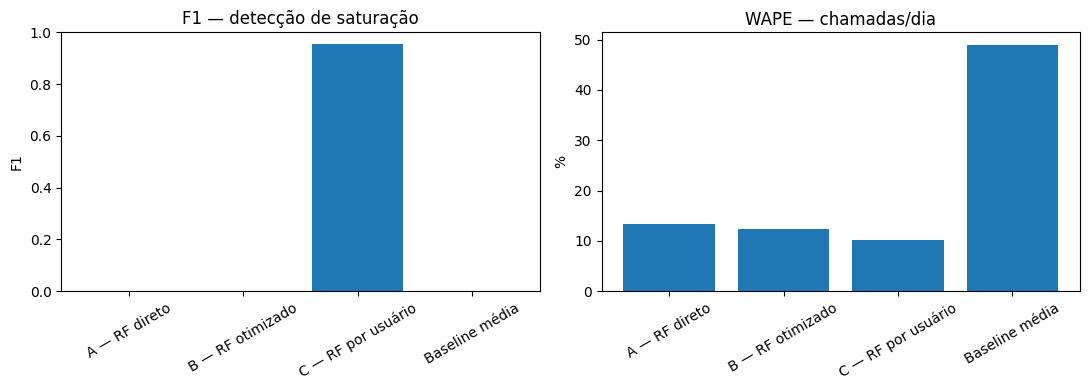

In [8]:
ranking=resumo.merge(metricas[metricas.alvo=='chamadas'][['modelo','WAPE_%','MAE_picos']],on='modelo')
ranking['F1_ord']=ranking.F1.fillna(-1)
ranking['MAE_dia_ord']=ranking.MAE_dia_condicional.fillna(np.inf)
ranking=ranking.sort_values(['F1_ord','recall','MAE_dia_ord','WAPE_%'],ascending=[False,False,True,True])
display(ranking[['modelo','F1','recall','precisao','MAE_dia_condicional','WAPE_%','MAE_picos']].round(3))
if ranking.iloc[0].TP==0:
    print('CONCLUSÃO: nenhum modelo identificou saturações reais; não há vencedor validado para a tarefa principal.')
else:
    print('Melhor modelo neste experimento sintético:',ranking.iloc[0].modelo)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].bar(resumo.modelo,resumo.F1.fillna(0));axs[0].set(title='F1 — detecção de saturação',ylabel='F1',ylim=(0,1))
axs[1].bar(metricas[metricas.alvo=='chamadas'].modelo,metricas[metricas.alvo=='chamadas']['WAPE_%']);axs[1].set(title='WAPE — chamadas/dia',ylabel='%')
for ax in axs:ax.tick_params(axis='x',rotation=30)
plt.tight_layout();plt.show()

### Limitações e próximos passos
- **Sem validação real:** dados sintéticos e cotas ilustrativas; nenhuma métrica demonstra desempenho em produção.
- **Simulador simplificado:** um único fluxo de chamadas e tokens por chamada uniformes; o backend real usa operações/modelos distintos, cotas por modelo/projeto, tentativas de fallback e possíveis resets/limites adicionais.
- **Projeção de usuários conhecida:** todos os modelos recebem o mesmo cenário hipotético. Prever aquisição de usuários é outro problema.
- **Hiperparâmetros:** B usa apenas treino e `TimeSeriesSplit`; teste final permanece separado. Otimização não garante melhoria.
- **Avaliação do evento:** F1/recall e falsos negativos são fundamentais; MAE da data só é interpretável junto da detecção.
- **Para produção:** instrumentar chave/projeto, modelo e operação, confirmar cotas efetivas, coletar histórico de muitos dias e validar em períodos futuros reais.